<a href="https://colab.research.google.com/github/Ajitkumar696/graduate-admission-prediction/blob/main/graduateadd.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
df=pd.read_csv("/content/Admission_Predict.csv")
df.head()
df.shape
df.info()
df.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Serial No.         400 non-null    int64  
 1   GRE Score          400 non-null    int64  
 2   TOEFL Score        400 non-null    int64  
 3   University Rating  400 non-null    int64  
 4   SOP                400 non-null    float64
 5   LOR                400 non-null    float64
 6   CGPA               400 non-null    float64
 7   Research           400 non-null    int64  
 8   Chance of Admit    400 non-null    float64
dtypes: float64(4), int64(5)
memory usage: 28.3 KB


np.int64(0)

In [ ]:
df.drop(columns=['Serial No.'], inplace=True)

In [ ]:
df.head()


,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,337,118,4,4.5,4.5,9.65,1,0.92
1,324,107,4,4.0,4.5,8.87,1,0.76
2,316,104,3,3.0,3.5,8.00,1,0.72
3,322,110,3,3.5,2.5,8.67,1,0.80
4,314,103,2,2.0,3.0,8.21,0,0.65


In [ ]:
X=df.iloc[:,0:-1]

In [ ]:
y=df.iloc[:,-1]

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=1)

In [ ]:
X

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research
0,337,118,4,4.5,4.5,9.65,1
1,324,107,4,4.0,4.5,8.87,1
2,316,104,3,3.0,3.5,8.00,1
3,322,110,3,3.5,2.5,8.67,1
4,314,103,2,2.0,3.0,8.21,0
...,...,...,...,...,...,...,...
395,324,110,3,3.5,3.5,9.04,1
396,325,107,3,3.0,3.5,9.11,1
397,330,116,4,5.0,4.5,9.45,1
398,312,103,3,3.5,4.0,8.78,0


In [ ]:
y

,Chance of Admit
0,0.92
1,0.76
2,0.72
3,0.80
4,0.65
...,...
395,0.82
396,0.84
397,0.91
398,0.67


In [ ]:
from sklearn.preprocessing import MinMaxScaler
scaler=MinMaxScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [ ]:
X_train_scaled

array([[0.22      , 0.17857143, 0.25      , ..., 0.42857143, 0.25      ,
        1.        ],
       [0.88      , 0.96428571, 1.        , ..., 0.85714286, 0.91911765,
        1.        ],
       [0.3       , 0.71428571, 0.5       , ..., 0.57142857, 0.53308824,
        0.        ],
       ...,
       [0.7       , 0.53571429, 0.5       , ..., 0.57142857, 0.70220588,
        1.        ],
       [0.72      , 0.67857143, 1.        , ..., 0.71428571, 0.74632353,
        1.        ],
       [0.2       , 0.46428571, 0.        , ..., 0.14285714, 0.22058824,
        0.        ]])

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(
    y_train.to_numpy().reshape(-1, 1),
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test.to_numpy().reshape(-1, 1),
    dtype=torch.float32
)

In [ ]:
class ANN(nn.Module):
    def __init__(self, input_features):
        super().__init__()

        self.hidden = nn.Linear(input_features, 7)
        self.output = nn.Linear(7, 1)

    def forward(self, x):
        x = torch.relu(self.hidden(x))
        x = self.output(x)
        return x

In [ ]:
model = ANN(X_train_tensor.shape[1])

print(model)

ANN(
  (layer1): Linear(in_features=7, out_features=16, bias=True)
  (layer2): Linear(in_features=16, out_features=8, bias=True)
  (output): Linear(in_features=8, out_features=1, bias=True)
)


In [ ]:
criterion = nn.MSELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
epochs = 200

for epoch in range(epochs):
    model.train()

    y_pred = model(X_train_tensor)
    loss = criterion(y_pred, y_train_tensor)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1}, Loss: {loss.item():.6f}")

Epoch 20, Loss: 0.421443
Epoch 40, Loss: 0.279183
Epoch 60, Loss: 0.145272
Epoch 80, Loss: 0.035655
Epoch 100, Loss: 0.005442
Epoch 120, Loss: 0.005726
Epoch 140, Loss: 0.005101
Epoch 160, Loss: 0.004903
Epoch 180, Loss: 0.004632
Epoch 200, Loss: 0.004406


In [ ]:
model.eval()

with torch.no_grad():
    y_pred = model(X_test_tensor)

In [ ]:
print("Predicted values:")
print(y_pred[:10])

print("Actual values:")
print(y_test_tensor[:10])

Predicted values:
tensor([[0.6889],
        [0.6746],
        [0.8140],
        [0.7860],
        [0.8530],
        [0.6474],
        [0.6440],
        [0.5423],
        [0.4815],
        [0.9105]])
Actual values:
tensor([[0.6700],
        [0.6400],
        [0.8000],
        [0.8100],
        [0.8600],
        [0.5800],
        [0.7300],
        [0.5600],
        [0.5400],
        [0.9400]])


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred_np = y_pred.numpy()
y_actual_np = y_test_tensor.numpy()

print("MAE:", mean_absolute_error(y_actual_np, y_pred_np))
print("MSE:", mean_squared_error(y_actual_np, y_pred_np))
print("RMSE:", np.sqrt(mean_squared_error(y_actual_np, y_pred_np)))
print("R2 Score:", r2_score(y_actual_np, y_pred_np))

MAE: 0.0489812009036541
MSE: 0.005025266669690609
RMSE: 0.07088911531180657
R2 Score: 0.7827140688896179


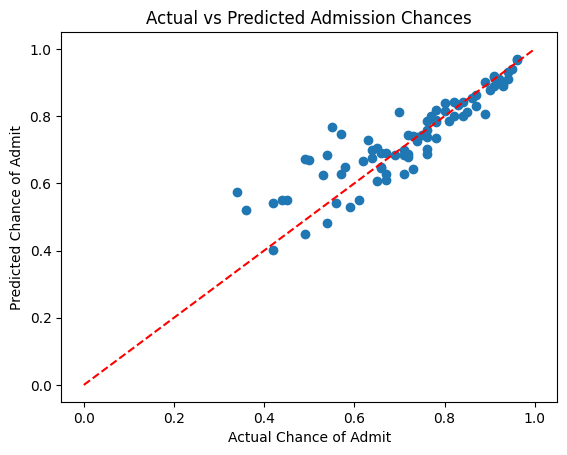

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(y_actual_np, y_pred_np)
plt.xlabel("Actual Chance of Admit")
plt.ylabel("Predicted Chance of Admit")
plt.title("Actual vs Predicted Admission Chances")
plt.plot([0, 1], [0, 1], 'r--')
plt.show()